<a href="https://colab.research.google.com/github/1drcodeai1/1drcodeai1-quant-finance-30-projects/blob/main/01_monte_carlo_stock_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Proyecto 1: Simulador Monte Carlo de Precios Accionarios con Validación en Datos Reales
En este cuaderno construimos un simulador de trayectorias de precios mediante Movimiento Geométrico Browniano (GBM) usando Google Colab y datos reales de mercado (yfinance), con validación estadística frente a datos históricos.

Instalación, importaciones y semilla aleatoria
Qué hace y cómo lo hace
Instala y carga librerías numéricas y gráficas (numpy, pandas, yfinance, matplotlib, scipy).

Fija una semilla (SEED = 42) con np.random.default_rng(SEED) para que las simulaciones aleatorias sean reproducibles cada vez que ejecutes el cuaderno.

In [ ]:
!pip install -q yfinance numpy pandas matplotlib scipy

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
TRADING_DAYS = 252  # Días bursátiles aproximados por año

Matemática del modelo y estimación de parámetros1. Ecuación diferencial del Movimiento Geométrico Browniano (GBM)Modelamos el precio $S_t$ como una difusión estocástica:$$dS_t = \mu S_t \, dt + \sigma S_t \, dW_t$$$\mu$: drift (tendencia o tasa de deriva instantánea).$\sigma$: volatilidad (desviación estándar anualizada de los retornos).$dW_t$: incremento de un movimiento browniano estándar, con $W_{t+\Delta t} - W_t = \sqrt{\Delta t}\,Z_t$ y $Z_t \sim \mathcal{N}(0, 1)$.
2. Solución exacta en pasos discretos ($\Delta t$)Aplicando el lema de Itô a $\ln(S_t)$, la actualización exacta en un paso $\Delta t$ es:$$S_{t+\Delta t} = S_t \exp\left(\left(\mu - \frac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z_t\right)$$El término $-\frac{1}{2}\sigma^2$ (la corrección de convexidad / Itô) surge porque el promedio del exponencial es mayor que el exponencial del promedio cuando hay volatilidad ($\sigma > 0$).3. Estimación desde datos realesSi definimos los retornos logarítmicos diarios $r_t = \ln(S_t / S_{t-1})$:Volatilidad anualizada estimada: $\hat{\sigma} = s_r \sqrt{252}$, donde $s_r$ es la desviación estándar muestral diaria.Drift anualizado estimado: $\hat{\mu} = \bar{r} \cdot 252 + \frac{1}{2}\hat{\sigma}^2$, donde $\bar{r}$ es el promedio diario de log-retornos.

Descarga de datos reales y calibración de parámetrosQué hace y cómo lo haceDescarga precios ajustados (auto_adjust=True) de un activo (por ejemplo, SPY) para evitar distorsiones por dividendos o splits.Calcula los log-retornos diarios y estima $\hat{\mu}$ y $\hat{\sigma}$ anualizados.

In [ ]:
TICKER = "SPY"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

raw = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
close = raw["Close"].squeeze().dropna()

# Retornos logarítmicos: r_t = ln(S_t / S_{t-1})
log_returns = np.log(close / close.shift(1)).dropna()

sigma_hat = float(log_returns.std(ddof=1) * np.sqrt(TRADING_DAYS))
mu_hat = float(log_returns.mean() * TRADING_DAYS + 0.5 * (sigma_hat ** 2))
s0 = float(close.iloc[-1])

print(f"Activo: {TICKER} | Días observados: {len(log_returns)}")
print(f"Último precio histórico (S0): {s0:.2f}")
print(f"Drift anualizado estimado (mu_hat): {mu_hat:.2%}")
print(f"Volatilidad anualizada estimada (sigma_hat): {sigma_hat:.2%}")

Activo: SPY | Días observados: 1506
Último precio histórico (S0): 681.69
Drift anualizado estimado (mu_hat): 16.16%
Volatilidad anualizada estimada (sigma_hat): 20.80%


Motor de simulación Monte Carlo
Qué hace y cómo lo hace
Genera una matriz de choques normales estándar de tamaño (horizon_days, n_sims) (filas = días futuros, columnas = trayectorias simuladas).

Acumula los incrementos logarítmicos con np.cumsum y aplica np.exp para obtener todas las trayectorias en una sola operación vectorizada (mucho más rápido que un bucle for en Python).

In [ ]:
def simulate_gbm_paths(
    s0: float,
    mu: float,
    sigma: float,
    horizon_days: int,
    n_sims: int,
    rng: np.random.Generator,
    trading_days: int = 252,
) -> np.ndarray:
    dt = 1.0 / trading_days
    z = rng.standard_normal((horizon_days, n_sims))
    drift_step = (mu - 0.5 * sigma**2) * dt
    diffusion_step = sigma * np.sqrt(dt) * z

    # Log-precio relativo acumulado: ln(S_t / S_0)
    cum_log_returns = np.cumsum(drift_step + diffusion_step, axis=0)
    log_path = np.vstack([np.zeros((1, n_sims)), cum_log_returns])
    return s0 * np.exp(log_path)

HORIZON_DAYS = 252  # Simulación a 1 año hábil
N_SIMS = 10_000

paths = simulate_gbm_paths(
    s0=s0,
    mu=mu_hat,
    sigma=sigma_hat,
    horizon_days=HORIZON_DAYS,
    n_sims=N_SIMS,
    rng=rng,
)

terminal_prices = paths[-1]
terminal_returns = (terminal_prices / s0) - 1.0

print(f"Media precio final (1 año): {terminal_prices.mean():.2f}")
print(f"Mediana precio final (1 año): {np.median(terminal_prices):.2f}")
print(f"Percentil 5% retorno a 1 año: {np.percentile(terminal_returns, 5):.2%}")
print(f"Percentil 95% retorno a 1 año: {np.percentile(terminal_returns, 95):.2%}")

Media precio final (1 año): 802.79
Mediana precio final (1 año): 784.75
Percentil 5% retorno a 1 año: -18.51%
Percentil 95% retorno a 1 año: 62.37%


Validación con datos reales (momentos, normalidad y cono de confianza)
Qué hace y cómo lo hace
Validación de distribución: Compara asimetría (skew) y curtosis (kurtosis en exceso, donde una normal vale 0.0) entre los retornos diarios históricos y los simulados.

Gráfico de validación: Muestra una muestra de trayectorias junto con las bandas de percentiles (P10–P90 y P25–P75) del cono de Monte Carlo.

=== Validación de retornos diarios ===
Real     -> media: 0.00056, std: 0.01310, skew: -0.56, excess kurt: 13.39
Simulado -> media: 0.00056, std: 0.01310, skew: 0.00, excess kurt: 0.00


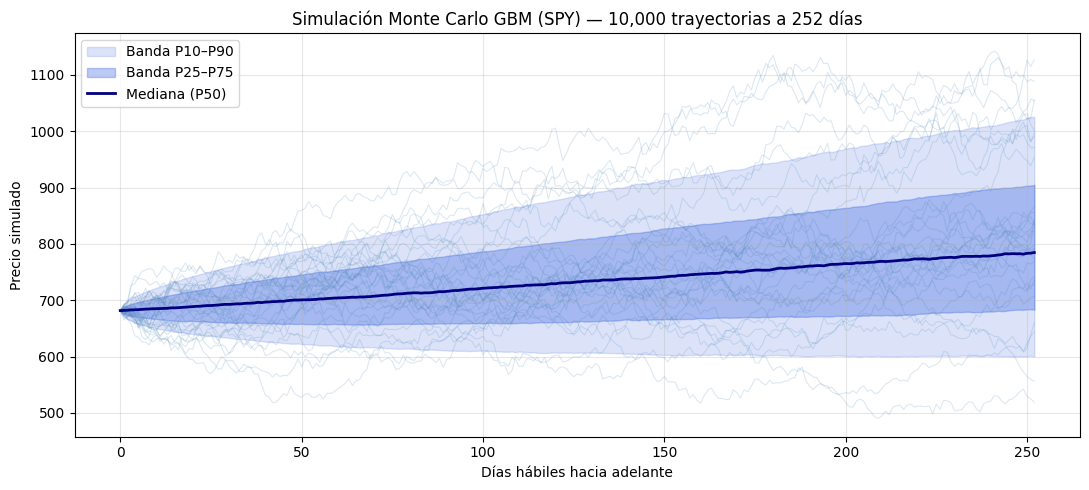

In [ ]:
sim_daily_log_ret = np.diff(np.log(paths), axis=0).ravel()

real_skew = stats.skew(log_returns)
real_kurt = stats.kurtosis(log_returns)  # exceso de curtosis (Normal = 0)
sim_skew = stats.skew(sim_daily_log_ret)
sim_kurt = stats.kurtosis(sim_daily_log_ret)

print("=== Validación de retornos diarios ===")
print(f"Real     -> media: {log_returns.mean():.5f}, std: {log_returns.std(ddof=1):.5f}, skew: {real_skew:.2f}, excess kurt: {real_kurt:.2f}")
print(f"Simulado -> media: {sim_daily_log_ret.mean():.5f}, std: {sim_daily_log_ret.std(ddof=1):.5f}, skew: {sim_skew:.2f}, excess kurt: {sim_kurt:.2f}")

# Percentiles a lo largo del horizonte
days_axis = np.arange(HORIZON_DAYS + 1)
p10, p25, p50, p75, p90 = np.percentile(paths, [10, 25, 50, 75, 90], axis=1)

plt.figure(figsize=(11, 5))
plt.plot(days_axis, paths[:, :30], color="steelblue", alpha=0.18, linewidth=0.8)
plt.fill_between(days_axis, p10, p90, color="royalblue", alpha=0.18, label="Banda P10–P90")
plt.fill_between(days_axis, p25, p75, color="royalblue", alpha=0.35, label="Banda P25–P75")
plt.plot(days_axis, p50, color="navy", linewidth=2, label="Mediana (P50)")
plt.title(f"Simulación Monte Carlo GBM ({TICKER}) — {N_SIMS:,} trayectorias a {HORIZON_DAYS} días")
plt.xlabel("Días hábiles hacia adelante")
plt.ylabel("Precio simulado")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()